In [18]:
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import numpy as np
import pandas as pd
import cartopy.crs as ccrs
import geopandas as gpd
from shapely.geometry import Polygon, MultiPolygon, Point
from shapely.ops import transform
import cartopy.feature as cfeature
import matplotlib.patheffects as pe
import textwrap
import matplotlib.colors as colors
import xarray as xr

In [19]:
# read in tc_basins file so we can filter to a specific ocean basin
polygons_dict = {}

with open("tc_basins_NAtl.dat", "r") as f:
    for line in f:
        line = line.strip()
        if not line or line.startswith("#"):
            continue

        parts = line.split(",")
        basin_name = parts[0].replace('"', '')
        n_vertices = int(parts[1])

        lon_vals = list(map(float, parts[2:2+n_vertices]))
        lat_vals = list(map(float, parts[2+n_vertices:2+2*n_vertices]))

        coords = list(zip(lon_vals, lat_vals))
        poly = Polygon(coords)

        if basin_name not in polygons_dict:
            polygons_dict[basin_name] = []
        polygons_dict[basin_name].append(poly)

# Convert to GeoDataFrame
basin_records = []

for name, poly_list in polygons_dict.items():
    if len(poly_list) == 1:
        geom = poly_list[0]
    else:
        geom = MultiPolygon(poly_list)

    basin_records.append({
        "basin name": name,
        "geometry": geom
    })

basins = gpd.GeoDataFrame(basin_records, crs="EPSG:4326")

# fix invalid polygons
basins["geometry"] = basins["geometry"].buffer(0)

# remove empy geometries
basins = basins[~basins.geometry.is_empty]

# read in tc_subbasins_NAtl file
sub_polygons_dict = {}

with open("tc_subbasins_NAtl_v5.dat", "r") as f:
    for line in f:
        line = line.strip()
        if not line or line.startswith("#"):
            continue

        parts = line.split(",")
        sub_basin_name = parts[0].replace('"', '')
        n_vertices = int(parts[1])

        lon_vals = list(map(float, parts[2:2+n_vertices]))
        lon_vals = [(lon + 180) % 360 - 180 for lon in lon_vals]
        lat_vals = list(map(float, parts[2+n_vertices:2+2*n_vertices]))

        coords = list(zip(lon_vals, lat_vals))
        poly = Polygon(coords)

        if sub_basin_name not in sub_polygons_dict:
            sub_polygons_dict[sub_basin_name] = []
        sub_polygons_dict[sub_basin_name].append(poly)

# Convert to GeoDataFrame
sub_basin_records = []

for name, poly_list in sub_polygons_dict.items():
    if len(poly_list) == 1:
        geom = poly_list[0]
    else:
        geom = MultiPolygon(poly_list)

    sub_basin_records.append({
        "sub_basin_name": name,
        "geometry": geom
    })

sub_basins = gpd.GeoDataFrame(sub_basin_records, crs="EPSG:4326",geometry="geometry")

# fix invalid polygons
sub_basins["geometry"] = sub_basins["geometry"].buffer(0)

# remove empty geometries
sub_basins = sub_basins[~sub_basins.geometry.is_empty]

# longitude conversion
import shapely.ops
def shift_lon(geom):
    return shapely.ops.transform(
        lambda x, y: (((x + 180) % 360) - 180, y),
        geom
    )

# shift lon
sub_basins["geometry"] = sub_basins["geometry"].apply(shift_lon)
basins["geometry"] = basins["geometry"].apply(shift_lon)

In [20]:
# load merged table
ds = pd.read_csv("datasets/SyCLoPS/tc+td_sst+rhum600+shear_merged_table_1981-2025.csv")

print(ds)

      Unnamed: 0     TID     LON    LAT              ISOTIME  LON_bin  \
0              0  366672  -67.00  30.75  1981-09-01 12:00:00    -70.0   
1              1  366804  -40.00  28.75  1981-09-04 09:00:00    -40.0   
2              2  366736  -66.50  22.25  1981-09-05 15:00:00    -70.0   
3              3  366815  -72.50   8.50  1981-09-05 18:00:00    -75.0   
4              4  366832 -103.00  38.00  1981-09-06 15:00:00   -105.0   
...          ...     ...     ...    ...                  ...      ...   
1580        1580  738311  -77.25  11.50  2024-10-14 09:00:00    -80.0   
1581        1581  738375   11.75  34.50  2024-10-18 18:00:00     10.0   
1582        1582  738407  -86.00  17.50  2024-10-18 21:00:00    -90.0   
1583        1583  738443  -72.00  21.25  2024-10-20 00:00:00    -75.0   
1584        1584  738430  -54.75  31.50  2024-10-20 09:00:00    -55.0   

      LAT_bin        date        sst       rhum      shear  
0        30.0  1981-09-01  26.108850  57.930000  31.887100  
1

In [21]:
# match subbasin to merged table
# convert LAT and LON to a new column Points which contains (lon, lat) and convert to a geo data frame so we can filter using polygons
points = gpd.GeoDataFrame(
    ds, 
    geometry = gpd.points_from_xy(ds.LON, ds.LAT),
    crs = "EPSG:4326"
)

# print(points)

# filter points to North Atlantic
filtered = gpd.sjoin(
    points,
    basins[basins["basin name"] == "N Atlantic"],
    how = "inner",
    predicate = "within"
)

# drop columns we dont need
filtered = filtered[['TID', 'LON', 'LAT', 'ISOTIME', 'sst', 'rhum', 'shear', 'geometry']]

# join sub basins
sb = gpd.sjoin(
    filtered,
    sub_basins[['sub_basin_name', 'geometry']],
    how='left',
    predicate='intersects'
)

print(sb)

         TID     LON    LAT              ISOTIME        sst       rhum  \
0     366672  -67.00  30.75  1981-09-01 12:00:00  26.108850  57.930000   
1     366804  -40.00  28.75  1981-09-04 09:00:00  26.014523   4.747498   
2     366736  -66.50  22.25  1981-09-05 15:00:00  29.380350   6.500000   
3     366815  -72.50   8.50  1981-09-05 18:00:00        NaN        NaN   
4     366832 -103.00  38.00  1981-09-06 15:00:00        NaN        NaN   
...      ...     ...    ...                  ...        ...        ...   
1580  738311  -77.25  11.50  2024-10-14 09:00:00  30.178684  50.687500   
1581  738375   11.75  34.50  2024-10-18 18:00:00  26.301000  77.875000   
1582  738407  -86.00  17.50  2024-10-18 21:00:00  29.957430  64.625000   
1583  738443  -72.00  21.25  2024-10-20 00:00:00  29.793814  34.062500   
1584  738430  -54.75  31.50  2024-10-20 09:00:00  26.330875  86.250000   

          shear             geometry  index_right         sub_basin_name  
0     31.887100    POINT (-67 30.75)

In [22]:
# load origin sub basin dataset
ds2 = pd.read_csv("datasets/SyCLoPS/tc_track_subbasin_table_withYear.csv")

print(ds2)

        TID  LON_start  LAT_start  LON_end  LAT_end  YEAR_start  YEAR_end  \
0      3923     -95.00      31.75   -95.00    31.75        1940      1940   
1      5175     -90.25      28.25   -92.50    35.50        1940      1940   
2      5290     -79.00      31.00   -82.00    37.00        1940      1940   
3      5385     -26.25      14.50   -51.50    34.75        1940      1940   
4      5369     -55.25      16.75   -63.25    18.25        1940      1940   
..      ...        ...        ...      ...      ...         ...       ...   
994  738105     -22.25      14.50   -22.25    14.50        2024      2024   
995  738407     -87.25      16.75   -91.25    17.25        2024      2024   
996  738443     -73.00      21.00   -62.25    38.50        2024      2024   
997  738694     -77.25      15.50   -91.75    25.75        2024      2024   
998  738961     -81.25      15.25   -88.00    17.25        2024      2024   

           sub_basin_start          sub_basin_end  
0                 Gulf 

In [23]:
# filter to TIDs that originate in Gulf B
ds2 = ds2[ds2["sub_basin_start"] == 'Gulf (B)']

print(ds2)

        TID  LON_start  LAT_start  LON_end  LAT_end  YEAR_start  YEAR_end  \
0      3923     -95.00      31.75   -95.00    31.75        1940      1940   
13    15080     -95.00      27.50   -88.00    38.50        1941      1941   
23    23229     -97.00      28.75   -97.00    28.75        1942      1942   
55    47621     -94.00      31.50   -94.00    31.50        1945      1945   
56    47765     -86.25      22.50   -69.00    40.00        1945      1945   
..      ...        ...        ...      ...      ...         ...       ...   
967  728385     -95.25      26.00  -103.00    29.50        2023      2023   
979  735571     -96.00      21.00   -95.75    20.75        2024      2024   
981  735727     -95.25      19.75   -96.75    20.25        2024      2024   
986  737369     -96.25      23.50   -91.50    35.50        2024      2024   
992  738084     -95.25      23.00   -58.50    30.50        2024      2024   

    sub_basin_start          sub_basin_end  
0          Gulf (B)           

In [26]:
# time series of average SSTs in Gulf A
sb = sb[sb["sub_basin_name"] == "Gulf (A)"]

# get TIDs of TCs that originated in Gulf B
gulf_b_tids = ds2.loc[
    ds2['sub_basin_start'] == 'Gulf (B)', 'TID'
]

# add a column to flag if the TC originated in Gulf B
sb['or_Gulf_B'] = sb['TID'].isin(gulf_b_tids)

print(sb)

         TID    LON    LAT              ISOTIME        sst       rhum  \
22    375415 -93.00  26.25  1982-09-09 03:00:00  29.266342  50.875000   
34    382066 -86.25  27.25  1983-06-21 06:00:00  27.471354  77.490005   
42    383006 -92.00  30.25  1983-08-02 12:00:00  26.670000        NaN   
45    383294 -88.75  28.00  1983-08-14 15:00:00  29.225082  54.682503   
75    392623 -90.75  26.50  1984-09-20 06:00:00  27.645380  77.125000   
...      ...    ...    ...                  ...        ...        ...   
1377  701943 -90.00  25.50  2020-07-23 06:00:00  29.617777  70.312500   
1411  709709 -90.50  27.50  2021-06-18 18:00:00  28.572628  63.250000   
1432  711719 -84.50  30.00  2021-09-09 03:00:00  28.478529  79.750000   
1492  726354 -86.50  27.25  2023-06-02 00:00:00  26.714035  62.562500   
1577  738115 -85.50  26.75  2024-10-07 00:00:00  29.209469  63.437500   

          shear              geometry  index_right sub_basin_name  \
22     8.662001     POINT (-93 26.25)           11    

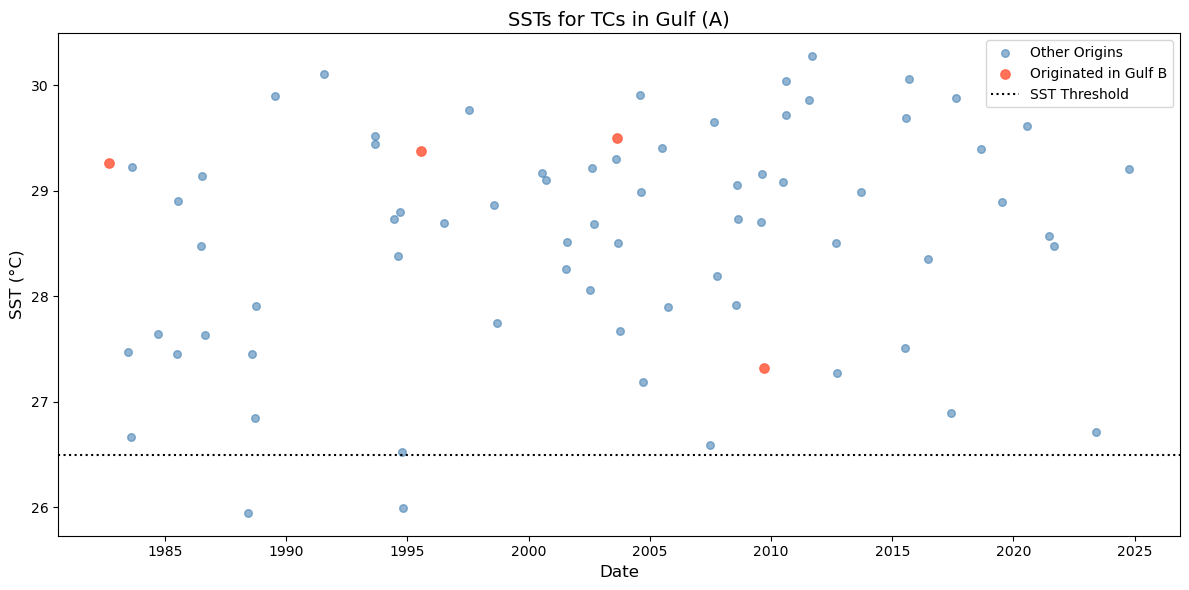

In [32]:
import matplotlib.pyplot as plt
import pandas as pd

# Convert ISOTIME to datetime
sb['ISOTIME'] = pd.to_datetime(sb['ISOTIME'])

# Remove rows with missing time or SST
sst_df = sb.dropna(subset=['ISOTIME', 'sst']).copy()

# Create scatter plot
plt.figure(figsize=(12, 6))

# TCs that did NOT originate in Gulf B
other_tcs = sst_df[sst_df['originated_Gulf_B'] == False]
plt.scatter(
    other_tcs['ISOTIME'],
    other_tcs['sst'],
    color='steelblue',
    alpha=0.6,
    s=30,
    label='Other Origins'
)

# TCs that DID originate in Gulf B
gulf_b_tcs = sst_df[sst_df['originated_Gulf_B'] == True]
plt.scatter(
    gulf_b_tcs['ISOTIME'],
    gulf_b_tcs['sst'],
    color='tomato',
    alpha=0.9,
    s=45,
    label='Originated in Gulf B'
)

# threshold line
plt.axhline(y=26.5, color='black', linestyle=':', linewidth=1.5,
            label='SST Threshold')

# Labels and formatting
plt.xlabel('Date', fontsize=12)
plt.ylabel('SST (°C)', fontsize=12)
plt.title('SSTs for TCs in Gulf (A)', fontsize=14)
plt.legend()
plt.tight_layout()

plt.savefig("images/data_viz/SST/avg_notAnom/Gulf_AvB_wSST_scatterplot.png")
plt.show()